# Import Library

In [60]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier

# Load Dataset

The sinking of the Titanic is one of the most infamous shipwrecks in history.

On April 15, 1912, during her maiden voyage, the widely considered “unsinkable” RMS Titanic sank after colliding with an iceberg. Unfortunately, there weren’t enough lifeboats for everyone on board, resulting in the death of 1502 out of 2224 passengers and crew.

While there was some element of luck involved in surviving, it seems some groups of people were more likely to survive than others.

In this challenge, we ask you to build a predictive model that answers the question: “what sorts of people were more likely to survive?” using passenger data (ie name, age, gender, socio-economic class, etc).

In [2]:
df = sns.load_dataset('titanic')
df_raw=df.copy() #save raw dataset

In [3]:
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


# Data Prepocessing

## Formatting and Encoding

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB


In [5]:
df[['survived','sex','pclass','class','alone','embark_town']]=df[['survived','sex','pclass','class','alone','embark_town',]].astype("category")
df_dummies = pd.get_dummies(df[['pclass', 'sex', 'embarked']], dtype=int) #encoding
df = pd.concat([df, df_dummies], axis=1)
df = df.drop(columns=['adult_male','alive','who'])

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 20 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    category
 1   pclass       891 non-null    category
 2   sex          891 non-null    category
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   deck         203 non-null    category
 10  embark_town  889 non-null    category
 11  alone        891 non-null    category
 12  pclass_1     891 non-null    int64   
 13  pclass_2     891 non-null    int64   
 14  pclass_3     891 non-null    int64   
 15  sex_female   891 non-null    int64   
 16  sex_male     891 non-null    int64   
 17  embarked_C   891 non-null    int64   
 18  embarked_Q   891 non-null    int64   
 19

In [7]:
df['id']=range(1,len(df)+1)
df['id']=df['id'].astype('int64')

## Missing Values

In [8]:
df.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
deck           688
embark_town      2
alone            0
pclass_1         0
pclass_2         0
pclass_3         0
sex_female       0
sex_male         0
embarked_C       0
embarked_Q       0
embarked_S       0
id               0
dtype: int64

In [9]:
df.dropna(subset=['age'],inplace=True)
df['deck'] = df['deck'].cat.add_categories([0]).fillna(0) #categorical [0] must be added
df['embark_town'] = df['embark_town'].cat.add_categories(['unknown']).fillna('unknown')

In [10]:
df.isna().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       2
class          0
deck           0
embark_town    0
alone          0
pclass_1       0
pclass_2       0
pclass_3       0
sex_female     0
sex_male       0
embarked_C     0
embarked_Q     0
embarked_S     0
id             0
dtype: int64

## Duplicate

In [11]:
df.duplicated().sum()

np.int64(0)

## Outlier Detection

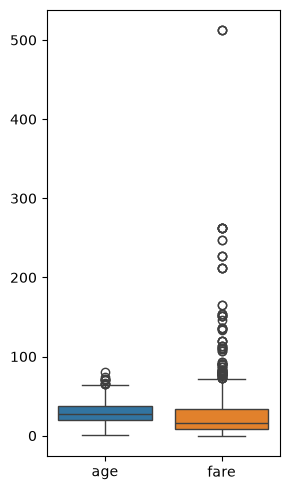

In [12]:
plt.figure(figsize=(3,5))
sns.boxplot(data=df.select_dtypes(include=['float64']))
plt.tight_layout()
plt.show()

## Feature Engineering

In [13]:
df['FamilySize'] = df['sibsp'] + df['parch'] + 1

In [14]:
df[['parch','sibsp']]=df[['parch','sibsp']].astype('category')

In [15]:
bins = [0,4,12,25,60,80]
labels = ['1 (Baby)','2 (Child)','3 (Young)','4 (Adult)','5 (Senior)']
df['Category Age']=pd.cut(df['age'],bins=bins,labels=labels,right=True)
df_dummies = pd.get_dummies(df['Category Age'],dtype=int)
df = pd.concat([df, df_dummies], axis=1)

| Category | Number | Range Age (`bins`) |
| --- | --- | --- |
| `Baby` | `1` | 0 – 4 years old |
| `Child` | `2` | 5 – 12 years old |
| `Young` | `3` | 13 – 25 years old |
| `Adult` | `4` | 26 – 60 years old |
| `Senior` | `5` | 61 – 80 years old |

In [16]:
df['id']=range(1,len(df)+1) #id
df['id']=df['id'].astype('int64')

In [17]:
df.info()

<class 'pandas.DataFrame'>
Index: 714 entries, 0 to 890
Data columns (total 28 columns):
 #   Column        Non-Null Count  Dtype   
---  ------        --------------  -----   
 0   survived      714 non-null    category
 1   pclass        714 non-null    category
 2   sex           714 non-null    category
 3   age           714 non-null    float64 
 4   sibsp         714 non-null    category
 5   parch         714 non-null    category
 6   fare          714 non-null    float64 
 7   embarked      712 non-null    str     
 8   class         714 non-null    category
 9   deck          714 non-null    category
 10  embark_town   714 non-null    category
 11  alone         714 non-null    category
 12  pclass_1      714 non-null    int64   
 13  pclass_2      714 non-null    int64   
 14  pclass_3      714 non-null    int64   
 15  sex_female    714 non-null    int64   
 16  sex_male      714 non-null    int64   
 17  embarked_C    714 non-null    int64   
 18  embarked_Q    714 non-null

## Save dataset

In [18]:
df_cleaned=df.copy()

# Objective

## Question

1. What is the total number of passengers in this dataset? How many survived, and how many did not? (Provide both absolute numbers and percentages)
2. What is the age distribution of the passengers? Create a histogram. What is the mean age? What is the median age? Are there any extreme outlier ages?
3. How many passengers are there per ticket class (`Pclass`)? Visualize this using a bar chart. Which class had the highest number of passengers?
4. What is the gender distribution of the passengers? What percentage are male vs. female? Visualize this using a pie chart.
5. From which ports did the passengers embark (`Embarked`)? Which port was the busiest/most crowded?
6. What is the mean ticket fare (`Fare`)? What is the median fare? 
7. Does gender affect survival rate? What percentage of females survived compared to males? Create a visualization.
8. Does ticket class (`Pclass`) affect survival? Which class (1st, 2nd, or 3rd) had the highest survival count/rate, and why?
9. Does age affect survival rate? Did children have a higher survival rate? Create a clear visualization.
10. Does the number of siblings/spouses (`SibSp`) affect survival? Are solo travelers more likely to survive?
11. Does the number of parents/children (`Parch`) affect survival?
12. Does the port of embarkation (`Embarked`) affect survival rate? 
13. What is the average ticket fare for passengers who survived versus those who did not? Did survivors pay higher fares?
14. Perform a combined analysis: **Gender + Pclass** $\rightarrow$ **Survival**. Which combination was most likely to survive?
15. Create a correlation matrix for all numerical columns. Which feature correlates most strongly with survival? Which features exhibit high multicollinearity?
16. Visualize relationships between features using a scatter plot matrix or a `pairplot`. What patterns do you observe?
17. Conduct a hypothesis test: Is there a statistically significant difference in mean age between passengers who survived and those who did not? (Use a two-sample *t-test*)
18. Build a simple baseline predictive model: Use *Logistic Regression* to predict passenger survival based on available features. What is its accuracy score?
19. Compare model performance: *Logistic Regression* vs. *Decision Tree* vs. *Random Forest*. Which model achieves the highest accuracy?
20. Feature Importance Analysis: What are the most important features for predicting survival? (Extract feature importances from the *Random Forest* model)
21. Actionable Recommendations: If you were a safety officer aboard the ship, what key lessons could you draw from this data to design better evacuation protocols?
22. Final Visual Dashboard: Select 3–5 of the best visualizations that most clearly tell the story of survival patterns. Combine them into a single dashboard layout 
23. Executive Summary Insights: Write down the top 5 most interesting findings from your analysis 
24. Final Conclusion: In a single concise paragraph, explain who was most likely to survive the Titanic disaster and why.
25. Critical Limitations & Future Scope: What are the main limitations of this dataset? What insights cannot be definitively concluded? What additional variables/features would you recommend adding to improve analysis?

## 1. What is the total number of passengers in this dataset? How many survived, and how many did not? (Provide both absolute numbers and percentages)

In [19]:
unsurvived_num = len(df[df['survived']==0])
survived_num = len(df[df['survived']==1])
unsurvived_pct = len(df[df['survived']==0])/len(df) *100
survived_pct = len(df[df['survived']==1])/len(df) *100

Total Passengers : 714 Passengers
Unsurvived       : 424 Passengers (59.38%)
Survived         : 290 Passengers (40.62%)


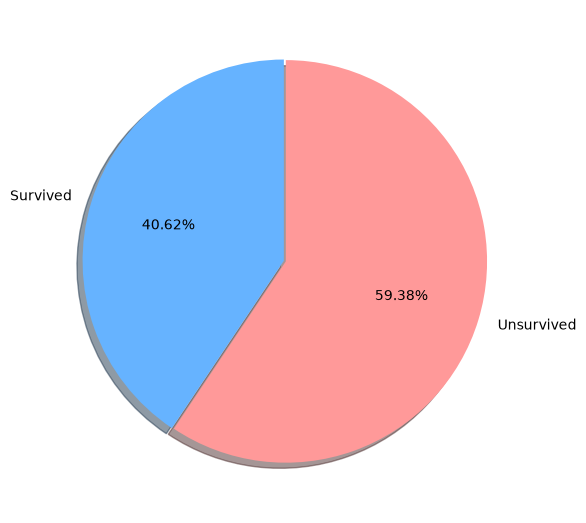

In [20]:
print(f"Total Passengers : {len(df)} Passengers")
print(f"Unsurvived       : {unsurvived_num} Passengers ({unsurvived_pct:.2f}%)")
print(f"Survived         : {survived_num} Passengers ({survived_pct:.2f}%)")


#visualize
labels = ['Survived', 'Unsurvived']
sizes = [survived_pct, unsurvived_pct]
colors = ['#66b3ff', '#ff9999']  
explode = (0.01, 0)
plt.figure(figsize=(6, 6))
plt.pie(sizes, labels=labels, autopct='%1.2f%%', colors=colors, 
        explode=explode, startangle=90, shadow=True)
plt.tight_layout()
plt.show()

## 2. What is the age distribution of the passengers? Create a histogram. What is the mean age? What is the median age? Are there any extreme outlier ages?

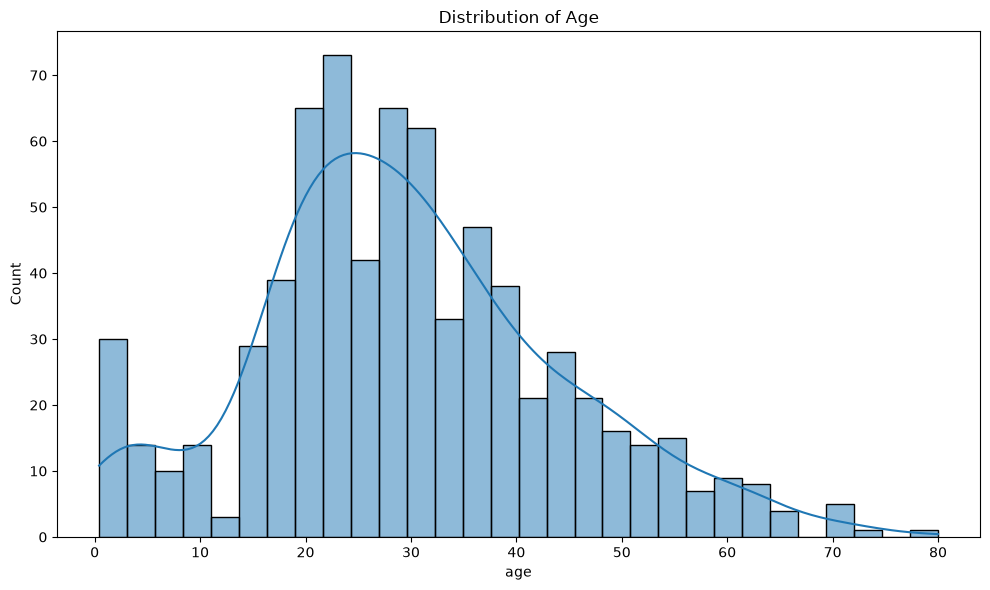

In [21]:
plt.figure(figsize=(10,6))
sns.histplot(df['age'],bins=30,kde=True)
plt.title('Distribution of Age')
plt.tight_layout()
plt.show()

In [22]:
avg = df['age'].mean()
med = df['age'].median()

Q1 = df['age'].quantile(0.25)
Q3 = df['age'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

extreme_lower = Q1 - 3 * IQR
extreme_upper = Q3 + 3 * IQR

outliers = df['age'][(df['age'] < extreme_lower) | (df['age'] > extreme_upper)]

print(
    f"""Mean Age :{avg:.2f}
Median Age :{med}
Outliers Count : {len(outliers)}
Outliers Values : {outliers.values}
    """)

Mean Age :29.70
Median Age :28.0
Outliers Count : 0
Outliers Values : []
    


## 3. How many passengers are there per ticket class (Pclass)? Visualize this using a bar chart. Which class had the highest number of passengers?

C:\Users\FARUQ\AppData\Local\Temp\ipykernel_18048\2326422131.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=df,x='pclass',palette='inferno')


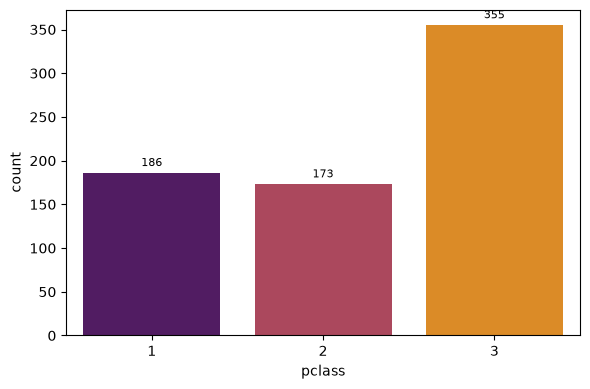

In [23]:
plt.figure(figsize=(6,4))
ax = sns.countplot(data=df,x='pclass',palette='inferno')
for p in ax.patches:
  ax.annotate(
      f'{int(p.get_height())}',
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha='center',
      va='bottom',
      fontsize=8,
      color='black',
      xytext=(0, 3),
      textcoords='offset points',
  )
plt.tight_layout()
plt.show()

## 4. What is the gender distribution of the passengers? What percentage are male vs. female? Visualize this using a pie chart.

<function matplotlib.pyplot.show(close=None, block=None)>

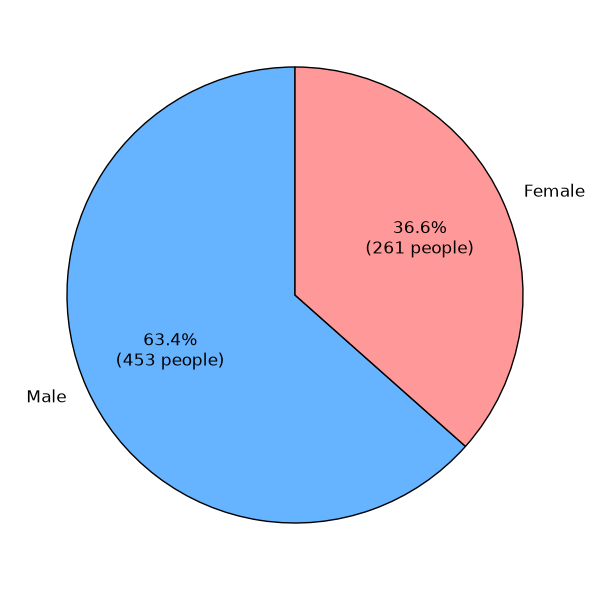

In [24]:
gender_counts = df['sex'].value_counts()

#autopct custom to show the real value
def make_autopct(values):
  def my_autopct(pct):
    total = sum(values)
    val = int(round(pct * total / 100.0))
    return f'{pct:.1f}%\n({val} people)'

  return my_autopct

plt.figure(figsize=(10,6))
plt.pie(
    gender_counts,
    labels=gender_counts.index.str.capitalize(),
    autopct=make_autopct(gender_counts),
    startangle=90,
    colors=colors,
    wedgeprops={'edgecolor': 'black', 'linewidth': 1},
    textprops={'fontsize': 12},
)

plt.tight_layout()
plt.show

## 5. From which ports did the passengers embark (Embarked)? Which port was the busiest/most crowded

C:\Users\FARUQ\AppData\Local\Temp\ipykernel_18048\2525829777.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  az  = sns.countplot(data=df,x='embark_town',palette='magma')


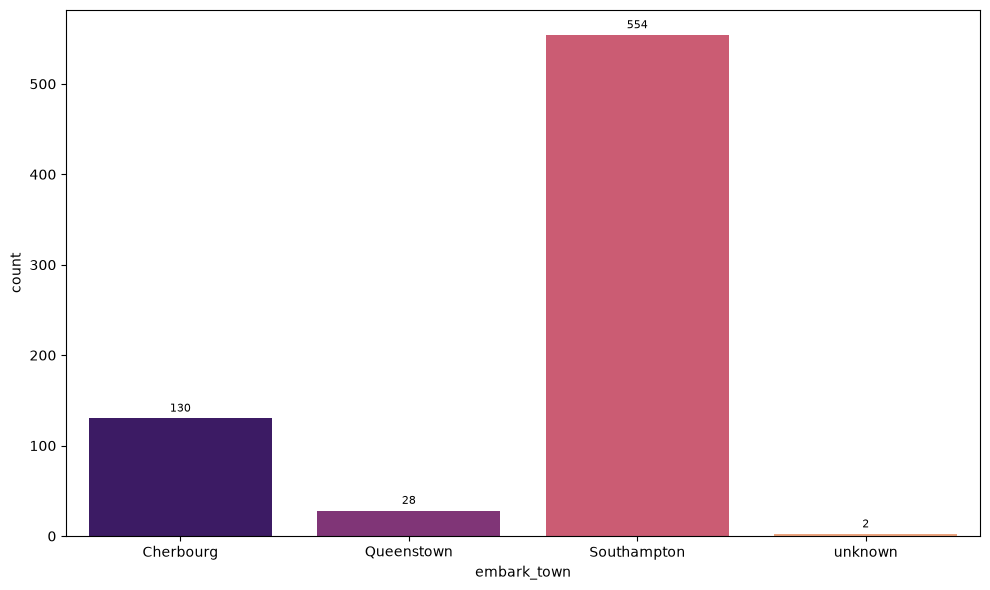

In [25]:
plt.figure(figsize=(10,6))
az  = sns.countplot(data=df,x='embark_town',palette='magma')
for p in az.patches:
  az.annotate(
      f'{int(p.get_height())}',
      (p.get_x() + p.get_width() / 2.0, p.get_height()),
      ha='center',
      va='bottom',
      fontsize=8,
      color='black',
      xytext=(0, 3),
      textcoords='offset points',
  )
plt.tight_layout()
plt.show()

## 6. What is the mean ticket fare (Fare)? What is the median fare?

In [26]:
avg_fare = df['fare'].mean()
med_fare = df['fare'].median()
print("Mean of Fare : ", avg_fare)
print("Median of Fare : ", avg_fare)

Mean of Fare :  34.694514005602244
Median of Fare :  34.694514005602244


## 7. Does gender affect survival rate? What percentage of females survived compared to males? Create a visualization.

C:\Users\FARUQ\AppData\Local\Temp\ipykernel_18048\1198603021.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x='sex',y='survived',errorbar=None,palette='magma')


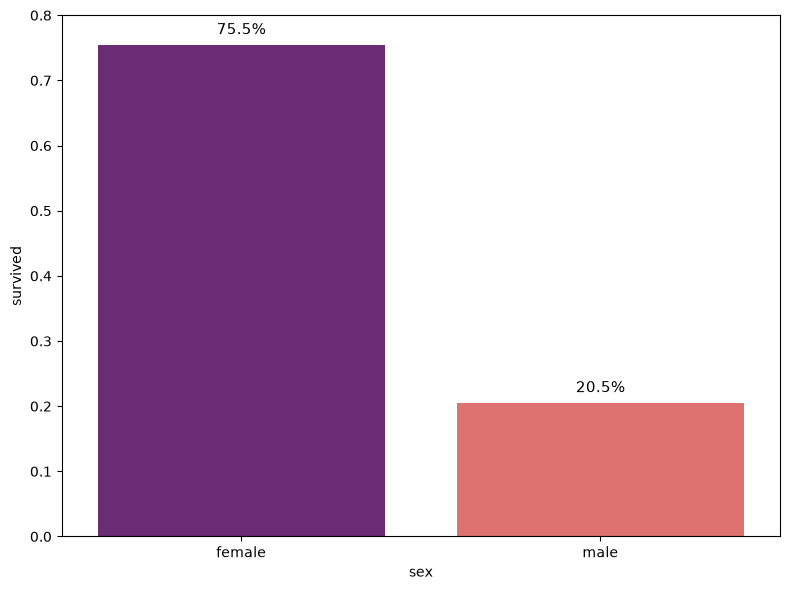

In [27]:
plt.figure(figsize=(8,6))
sns.barplot(data=df,x='sex',y='survived',errorbar=None,palette='magma')
for p in plt.gca().patches:
  height = p.get_height()
  if not pd.isna(height) and height > 0:
    plt.gca().annotate(
        f'{height * 100:.1f}%',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=11,
        xytext=(0, 5),
        textcoords='offset points',
    )
plt.ylim(0,0.8)
plt.tight_layout()
plt.show()

## 8. Does ticket class (Pclass) affect survival? Which class (1st, 2nd, or 3rd) had the highest survival count/rate, and why?

C:\Users\FARUQ\AppData\Local\Temp\ipykernel_18048\3759553456.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x='pclass',y='survived',errorbar=None,palette='inferno')


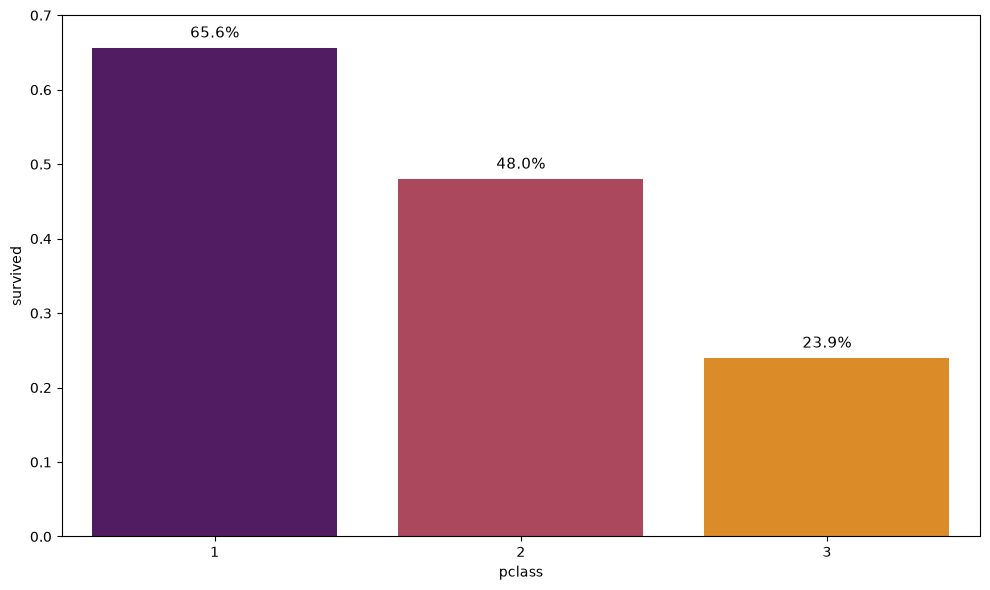

In [28]:
plt.figure(figsize=(10,6))
sns.barplot(data=df,x='pclass',y='survived',errorbar=None,palette='inferno')
for p in plt.gca().patches:
  height = p.get_height()
  if not pd.isna(height) and height > 0:
    plt.gca().annotate(
        f'{height * 100:.1f}%',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=11,
        xytext=(0, 5),
        textcoords='offset points',
    )
plt.ylim(0,0.7)
plt.tight_layout()
plt.show()

## 9. Does age affect survival rate? Did children have a higher survival rate? Create a clear visualization.

C:\Users\FARUQ\AppData\Local\Temp\ipykernel_18048\1735208682.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x='Category Age',y='survived',errorbar=None,palette='viridis')


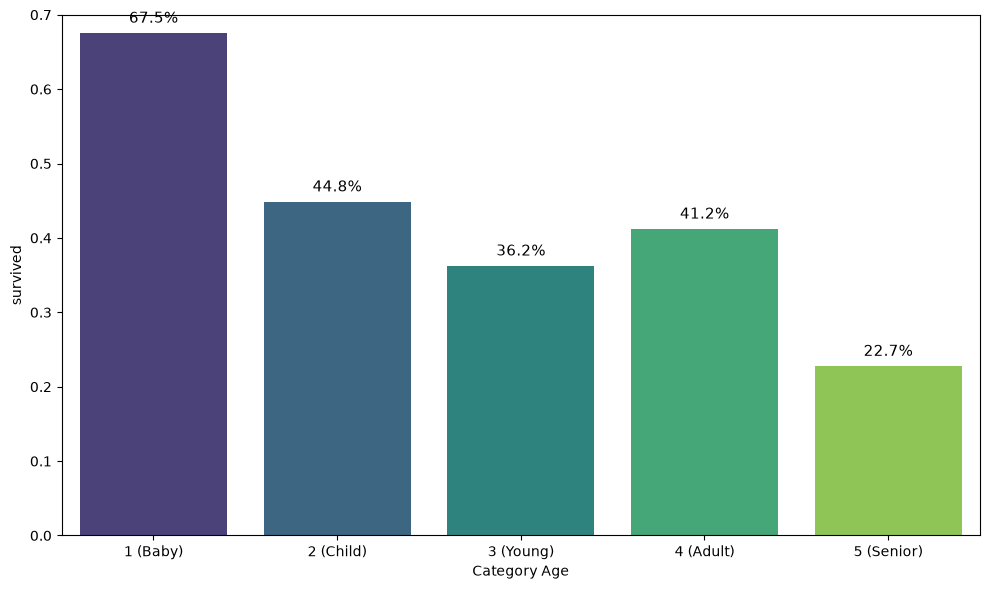

In [29]:
plt.figure(figsize=(10,6))
sns.barplot(data=df,x='Category Age',y='survived',errorbar=None,palette='viridis')
plt.ylim(0,0.7)
for p in plt.gca().patches:
  height = p.get_height()
  if not pd.isna(height) and height > 0:
    plt.gca().annotate(
        f'{height * 100:.1f}%',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=11,
        xytext=(0, 5),
        textcoords='offset points',
    )
plt.tight_layout()
plt.show()

| Category | Number | Range Age (`bins`) |
| --- | --- | --- |
| `Baby` | `1` | 0 – 4 tahun |
| `Child` | `2` | 5 – 12 tahun |
| `Young` | `3` | 13 – 25 tahun |
| `Adult` | `4` | 26 – 60 tahun |
| `Senior` | `5` | 61 – 80 tahun |

## 10. Does the number of siblings/spouses (SibSp) affect survival? Are solo travelers more likely to survive?

C:\Users\FARUQ\AppData\Local\Temp\ipykernel_18048\199176155.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='sibsp', y='survived', palette='Blues_d', ax=axes[0], errorbar=None)
C:\Users\FARUQ\AppData\Local\Temp\ipykernel_18048\199176155.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x='alone',y='survived',palette='Set2',ax=axes[1],errorbar=None)


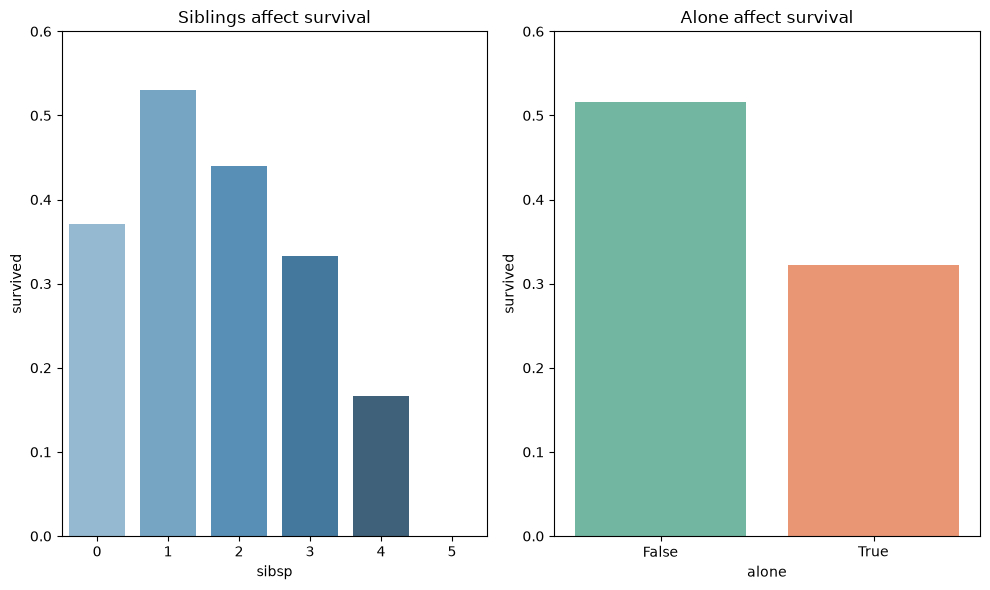

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(10, 6))

sns.barplot(data=df, x='sibsp', y='survived', palette='Blues_d', ax=axes[0], errorbar=None)
axes[0].set_title('Siblings affect survival')
axes[0].set_ylim(0, 0.6)

sns.barplot(data=df,x='alone',y='survived',palette='Set2',ax=axes[1],errorbar=None)
axes[1].set_title('Alone affect survival')
axes[1].set_ylim(0, 0.6)

plt.tight_layout()
plt.show()

## 11. Does the number of parents/children (Parch) affect survival?

C:\Users\FARUQ\AppData\Local\Temp\ipykernel_18048\4111045221.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x='parch',y='survived',errorbar=None,palette='magma')


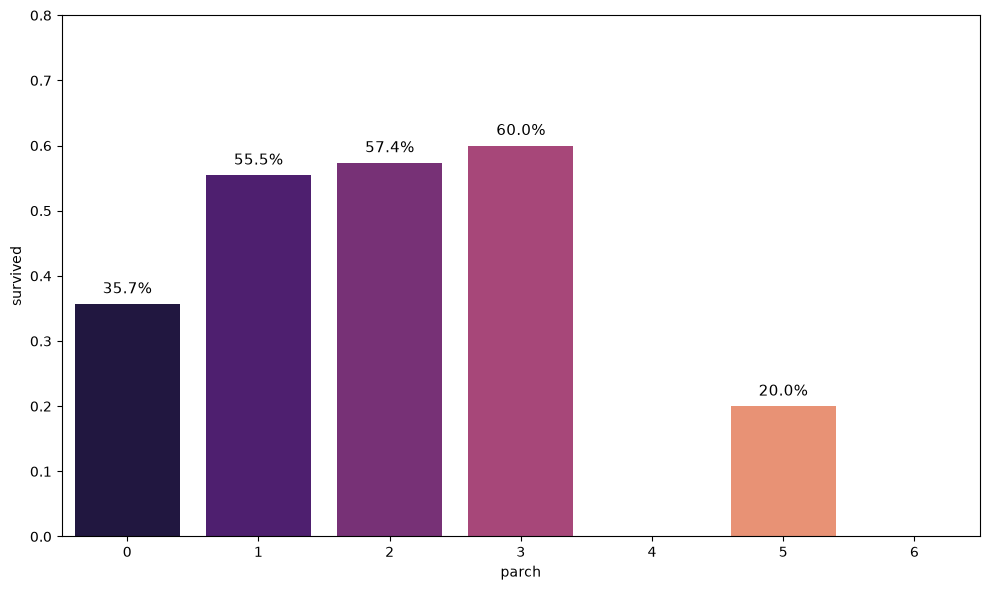

In [31]:
plt.figure(figsize=(10,6))
sns.barplot(data=df,x='parch',y='survived',errorbar=None,palette='magma')
for p in plt.gca().patches:
  height = p.get_height()
  if not pd.isna(height) and height > 0:
    plt.gca().annotate(
        f'{height * 100:.1f}%',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=11,
        xytext=(0, 5),
        textcoords='offset points',
    )
plt.ylim(0,0.8)
plt.tight_layout()
plt.show()

## 12. Does the port of embarkation (Embarked) affect survival rate? 

C:\Users\FARUQ\AppData\Local\Temp\ipykernel_18048\3678680112.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x='embark_town',y='survived',errorbar=None,palette='inferno')


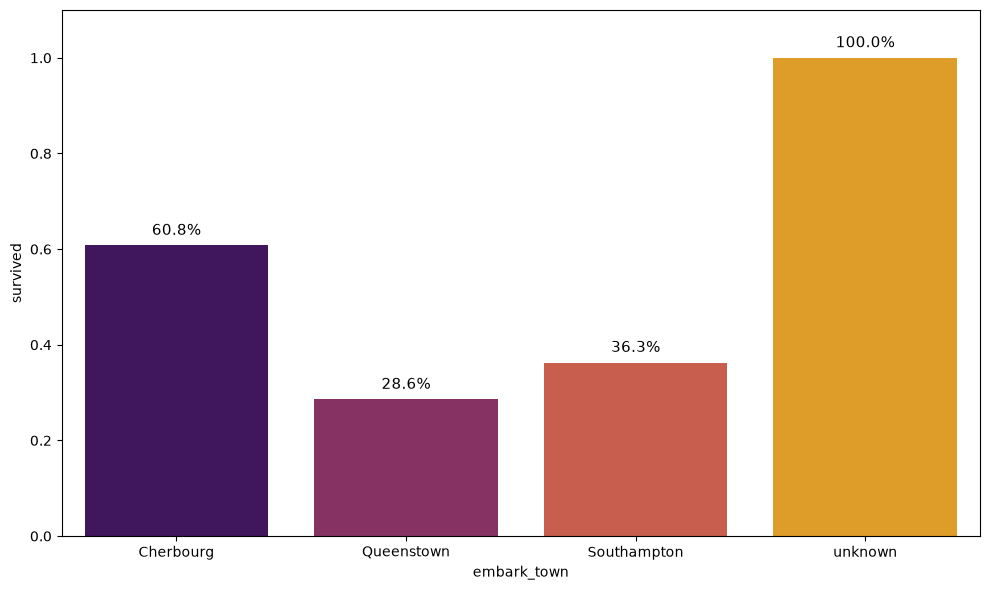

In [32]:
plt.figure(figsize=(10,6))
sns.barplot(data=df,x='embark_town',y='survived',errorbar=None,palette='inferno')
for p in plt.gca().patches:
  height = p.get_height()
  if not pd.isna(height) and height > 0:
    plt.gca().annotate(
        f'{height * 100:.1f}%',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=11,
        xytext=(0, 5),
        textcoords='offset points',
    )
plt.ylim(0,1.1)
plt.tight_layout()
plt.show()

## 13. What is the average ticket fare for passengers who survived versus those who did not? Did survivors pay higher fares?

In [33]:
df.groupby('survived')['fare'].mean()

survived
0    22.965456
1    51.843205
Name: fare, dtype: float64

C:\Users\FARUQ\AppData\Local\Temp\ipykernel_18048\2149619823.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x='survived',y='fare',errorbar=None,palette='viridis')


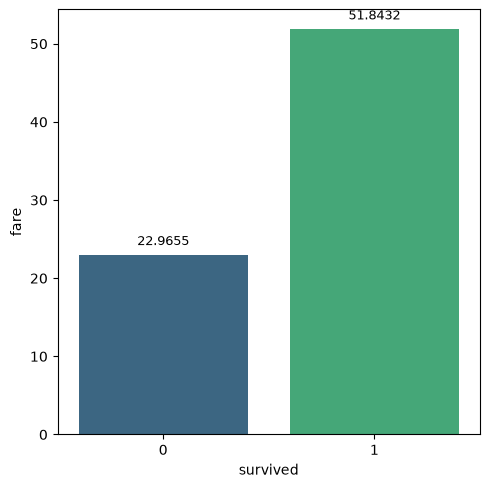

In [34]:
plt.figure(figsize=(5,5))
sns.barplot(data=df,x='survived',y='fare',errorbar=None,palette='viridis')
for p in plt.gca().patches:
  height = p.get_height()
  if not pd.isna(height) and height > 0:
    plt.gca().annotate(
        f'{height :.4f}',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=9,
        xytext=(0, 5),
        textcoords='offset points',
    )
plt.tight_layout()
plt.show()

## 14. Perform a combined analysis: Gender + Pclass to Survival. Which combination was most likely to survive?

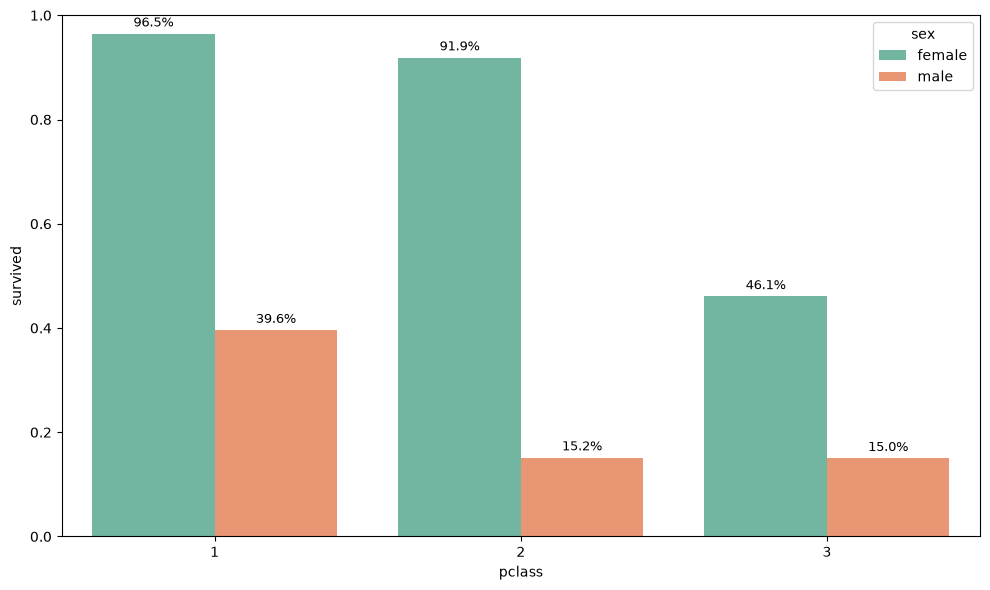

In [35]:
plt.figure(figsize=(10,6))
sns.barplot(data=df, x='pclass', y='survived', hue='sex', palette='Set2', errorbar=None)
plt.ylim(0,1)
for p in plt.gca().patches:
  height = p.get_height()
  if not pd.isna(height) and height > 0:
    plt.gca().annotate(
        f'{height * 100:.1f}%',
        (p.get_x() + p.get_width() / 2.0, height),
        ha='center',
        va='bottom',
        fontsize=9,
        xytext=(0, 3),
        textcoords='offset points',
    )
plt.tight_layout()
plt.show()

## 15. Create a correlation matrix for all numerical columns. Which feature correlates most strongly with survival? Which features exhibit high multicollinearity?

In [36]:
df['survived_num']=df['survived'].copy().astype(int)
num_df=df.select_dtypes(include=['number'])

In [37]:
corr_matrix=num_df.corr()
print(corr_matrix['survived_num'].sort_values(ascending=False))

survived_num    1.000000
sex_female      0.538826
pclass_1        0.301831
fare            0.268189
embarked_C      0.193607
1 (Baby)        0.133354
pclass_2        0.084753
FamilySize      0.042787
id              0.029720
2 (Child)       0.017644
4 (Adult)       0.012551
embarked_Q     -0.049549
3 (Young)      -0.062289
5 (Senior)     -0.064947
age            -0.077221
embarked_S     -0.164235
pclass_3       -0.337587
sex_male       -0.538826
Name: survived_num, dtype: float64


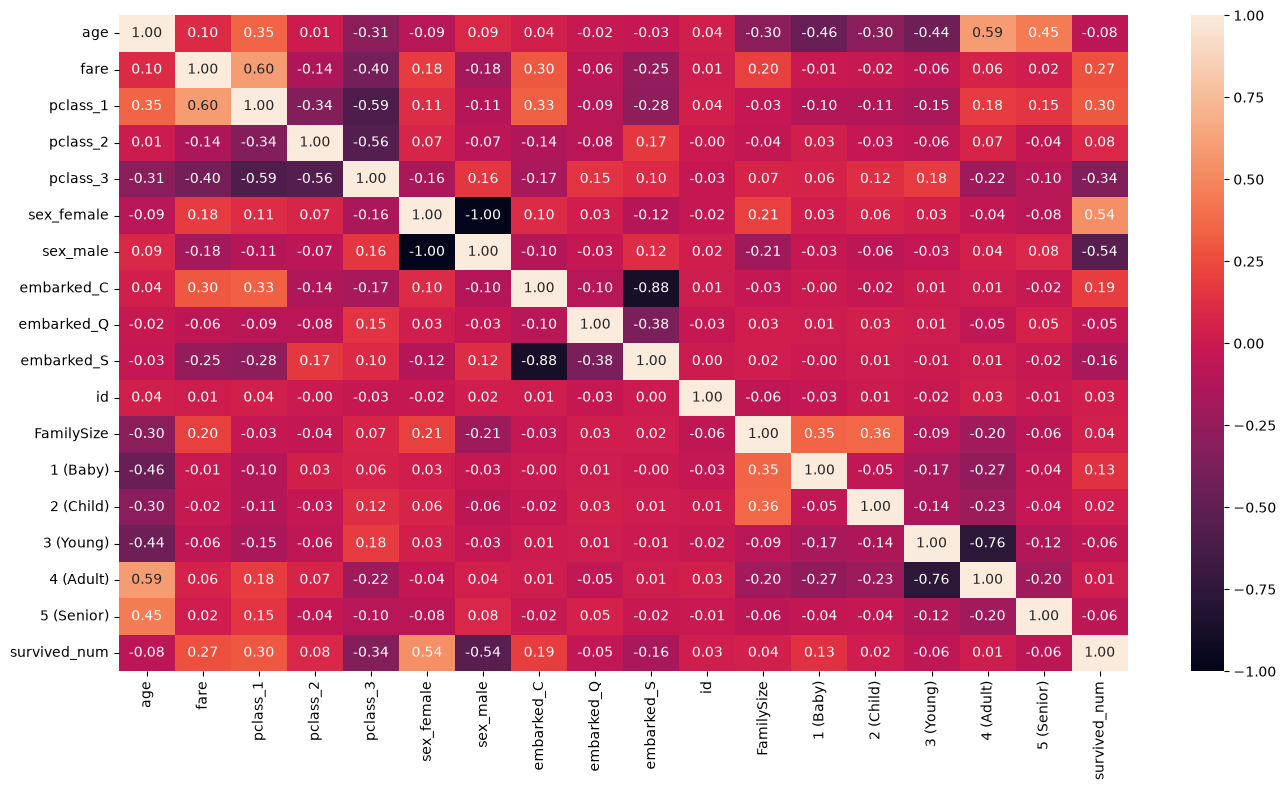

In [38]:
plt.figure(figsize=(14,8))
sns.heatmap(corr_matrix,annot=True,fmt='.2f')
plt.tight_layout()
plt.show()

## 16. Visualize relationships between features using a scatter plot matrix or a pairplot. What patterns do you observe?

<Figure size 1400x800 with 0 Axes>

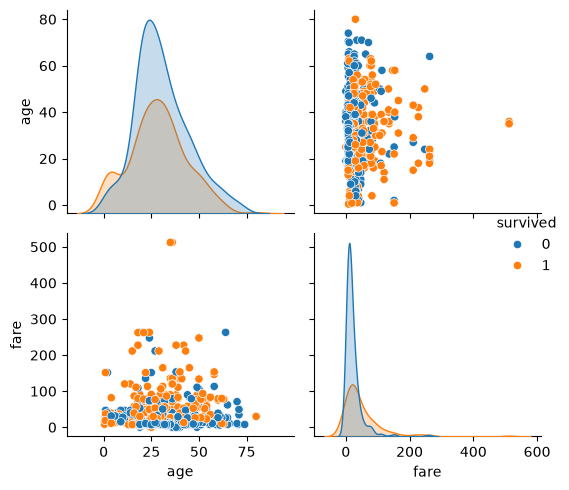

In [39]:
cols=['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']

plt.figure(figsize=(14,8))
sns.pairplot(df[cols],hue='survived',diag_kind='kde')

plt.tight_layout()
plt.show()

## 17. Conduct a hypothesis test: Is there a statistically significant difference in mean age between passengers who survived and those who did not? (Use a two-sample t-test)

$H_0$ (Null Hypothesis): Tidak ada perbedaan yang signifikan secara statistik antara rata-rata usia penumpang yang selamat dan yang tidak selamat ($\mu_{\text{survived}} = \mu_{\text{not survived}}$)  
$H_1$ (Alternative Hypothesis): Ada perbedaan yang signifikan secara statistik antara rata-rata usia penumpang yang selamat dan yang tidak selamat ($\mu_{\text{survived}} \neq \mu_{\text{not survived}}$).

In [40]:
age_survived = df[df['survived'] == 1]['age']
age_not_survived = df[df['survived'] == 0]['age']

In [41]:
# two sample testing
t_stat, p_value = stats.ttest_ind(
    age_survived, age_not_survived, equal_var=False
)
p_value

np.float64(0.04118965162586639)

Dengan alpha 5%, tolak H0. ada perbedaan antara rata-rata usia penumpang yang selamat dan yang tidak selamat

## 18. Build a simple baseline predictive model: Use Logistic Regression to predict passenger survival based on available features. What is its accuracy score?

In [70]:
feature_cols =['pclass_1','pclass_2','pclass_3','sex_female','sex_male','age','fare','embarked_C','embarked_Q','embarked_S','FamilySize','alone']
X = df[feature_cols]
y = df['survived_num']

In [48]:
#train test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1, stratify=y)

In [55]:
#make a model
model = LogisticRegression(max_iter=1000, random_state=1)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.81      0.85      0.83        85
           1       0.76      0.71      0.73        58

    accuracy                           0.79       143
   macro avg       0.78      0.78      0.78       143
weighted avg       0.79      0.79      0.79       143



Accuracy Score is 79%

## 19. Compare model performance: Logistic Regression vs. Decision Tree vs. Random Forest. Which model achieves the highest accuracy?

In [61]:
#make a models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=1),
    'Decision Tree': DecisionTreeClassifier(random_state=1, max_depth=5),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=1, max_depth=5)
}

In [68]:
results = {}
print ('Accuracy Score')
for name, model in models.items():
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  acc = accuracy_score(y_test, y_pred)
  results[name] = acc
  print(f'{name:<30} : {acc * 100:.2f}%')

Accuracy Score
Logistic Regression            : 79.02%
Decision Tree                  : 73.43%
Random Forest                  : 76.92%


## 20. Feature Importance Analysis: What are the most important features for predicting survival? (Extract feature importances from the Random Forest model)

In [75]:
rf_model = models['Random Forest']
importances = rf_model.feature_importances_
feature_importance = pd.DataFrame({'Feature': feature_cols, 'Importance': importances}).sort_values(by='Importance', ascending=False)

In [87]:
feature_importance['Cumulative'] = (feature_importance['Importance'].cumsum() * 100)

In [95]:
print('Feature Importance Ranking')
for index, row in feature_importance.iterrows():
  print(f"{row['Feature']:<15} : {row['Importance'] * 100:<5.2f}%    {row['Cumulative']:<6.2f}%")

Feature Importance Ranking
sex_male        : 26.00%    26.00 %
sex_female      : 20.82%    46.82 %
fare            : 13.98%    60.81 %
age             : 11.98%    72.78 %
pclass_3        : 10.05%    82.84 %
FamilySize      : 5.10 %    87.94 %
pclass_1        : 4.86 %    92.80 %
pclass_2        : 2.53 %    95.33 %
embarked_C      : 2.11 %    97.44 %
alone           : 1.44 %    98.88 %
embarked_S      : 0.83 %    99.71 %
embarked_Q      : 0.29 %    100.00%


### Visualize

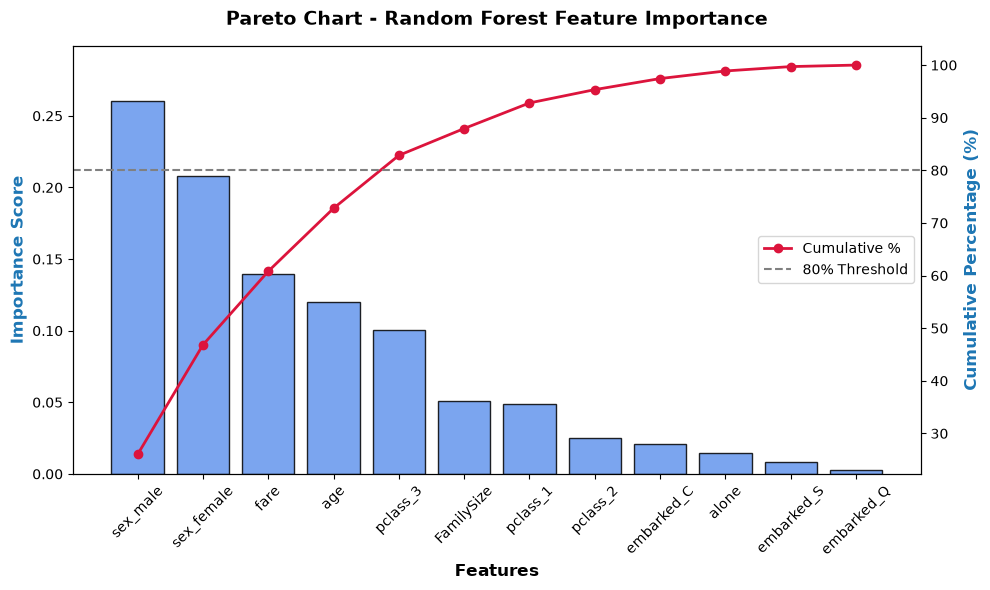

In [86]:
fig, ax1 = plt.subplots(figsize=(10, 6))

# Y axes left for Importance Individu
ax1.set_xlabel('Features', fontsize=12, fontweight='bold')
ax1.set_ylabel('Importance Score', color=color, fontsize=12, fontweight='bold')
bars = ax1.bar(
    feature_importance['Feature'],
    feature_importance['Importance'],
    color='cornflowerblue',
    alpha=0.85,
    edgecolor='black',
)
ax1.tick_params(axis='x', rotation=45)
ax1.set_ylim(0, feature_importance_df['Importance'].max() * 1.15)

# Y axes right for Cumulative Percentage
ax2 = ax1.twinx()
ax2.set_ylabel('Cumulative Percentage (%)', color=color, fontsize=12, fontweight='bold')
line = ax2.plot(
    feature_importance['Feature'],
    feature_importance['Cumulative'],
    color='crimson',
    marker='o',
    linewidth=2,
    markersize=6,
    label='Cumulative %')

# Pareto Line
ax2.axhline(y=80, color='gray', linestyle='--', linewidth=1.5, label='80% Threshold')

plt.title('Pareto Chart - Random Forest Feature Importance',fontsize=14,fontweight='bold',pad=15,)
ax2.legend(loc='center right')
plt.tight_layout()
plt.show()

## 21. Actionable Recommendations: If you were a safety officer aboard the ship, what key lessons could you draw from this data to design better evacuation protocols?

Based on the analysis of Titanic passenger data and the survival patterns demonstrated in the dataset, a safety officer can draw several critical lessons to modernize and optimize modern maritime evacuation protocols:

**1. Eliminate Class-Based Evacuation Bottlenecks**
Passengers in 1st Class had significantly higher survival rates compared to 2nd and 3rd Class passengers, largely due to the physical location of their cabins closer to the boat deck and preferential access during the crisis. To address this issue, modern ship design and evacuation procedures must ensure that accommodation location does not dictate survival probability. Escape routes from lower-tier or budget accommodations must be direct, unobstructed, and engineered to provide equal transit time to muster stations as premium cabins.premium cabins.

**2. Standardize Equitable Access to Life-Saving Assets**
The root catastrophe was compounded by an absolute shortage of lifeboats relative to the total number of passengers and crew on board. Consequently, strict adherence to regulatory compliance requiring 100% lifeboat capacity, along with mandatory safety margins for every individual on board, must be enforced. Furthermore, assignment to specific lifeboats must be dynamically managed to prevent overcrowding at specific stations and guarantee equal access to survival craft.

**3. Clear Prioritization and Support for Vulnerable Groups**
Predictive models consistently identify gender and age as the strongest predictive features of survival, reflecting the historical implementation of the "women and children first" protocol. While modern evacuation standards emphasize overall equity, emergency protocols must incorporate dedicated assistance teams and expedited pathways for children, the elderly, and mobility-impaired passengers. This ensures that vulnerable groups reach safety efficiently without relying on ad-hoc chivalry or unstructured decision-making during panic.

**4. Account for Family Group Dynamics**
Features measuring household composition indicate that travelers navigating evacuation as part of a family unit faced different logistical challenges compared to solo travelers. Safety and muster drills must educate passengers on family reunification points and clear communication procedures prior to departure. Protocols should be specially designed to prevent individuals from becoming trapped or delayed due to disorganized searching for family members during an active emergency.

**5. Decentralized Muster Stations and Clear Signage**
Panic and confusion are severely exacerbated when passengers are unfamiliar with ship layouts or must travel long, vertical distances through complex corridors to reach safety. Implementing decentralized, multi-level muster stations closer to passenger accommodation zones mitigates this risk. These stations should be backed by high-visibility, luminescent, and dynamic digital signage that actively directs evacuees away from blocked or compromised hazard zones.

## 22. Final Visual Dashboard: Select 3–5 of the best visualizations that most clearly tell the story of survival patterns. Combine them into a single dashboard layout

In [98]:
df['FamilySize']=df['FamilySize'].astype('category')

C:\Users\FARUQ\AppData\Local\Temp\ipykernel_18048\428523273.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x='sex',y='survived',ax=axes[0, 0],palette='Set2',errorbar=None)
C:\Users\FARUQ\AppData\Local\Temp\ipykernel_18048\428523273.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x='pclass', y='survived', ax=axes[0, 1],palette='viridis',errorbar=None)
C:\Users\FARUQ\AppData\Local\Temp\ipykernel_18048\428523273.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df,x='FamilySize',y='survived',ax=axes[1, 1],palet

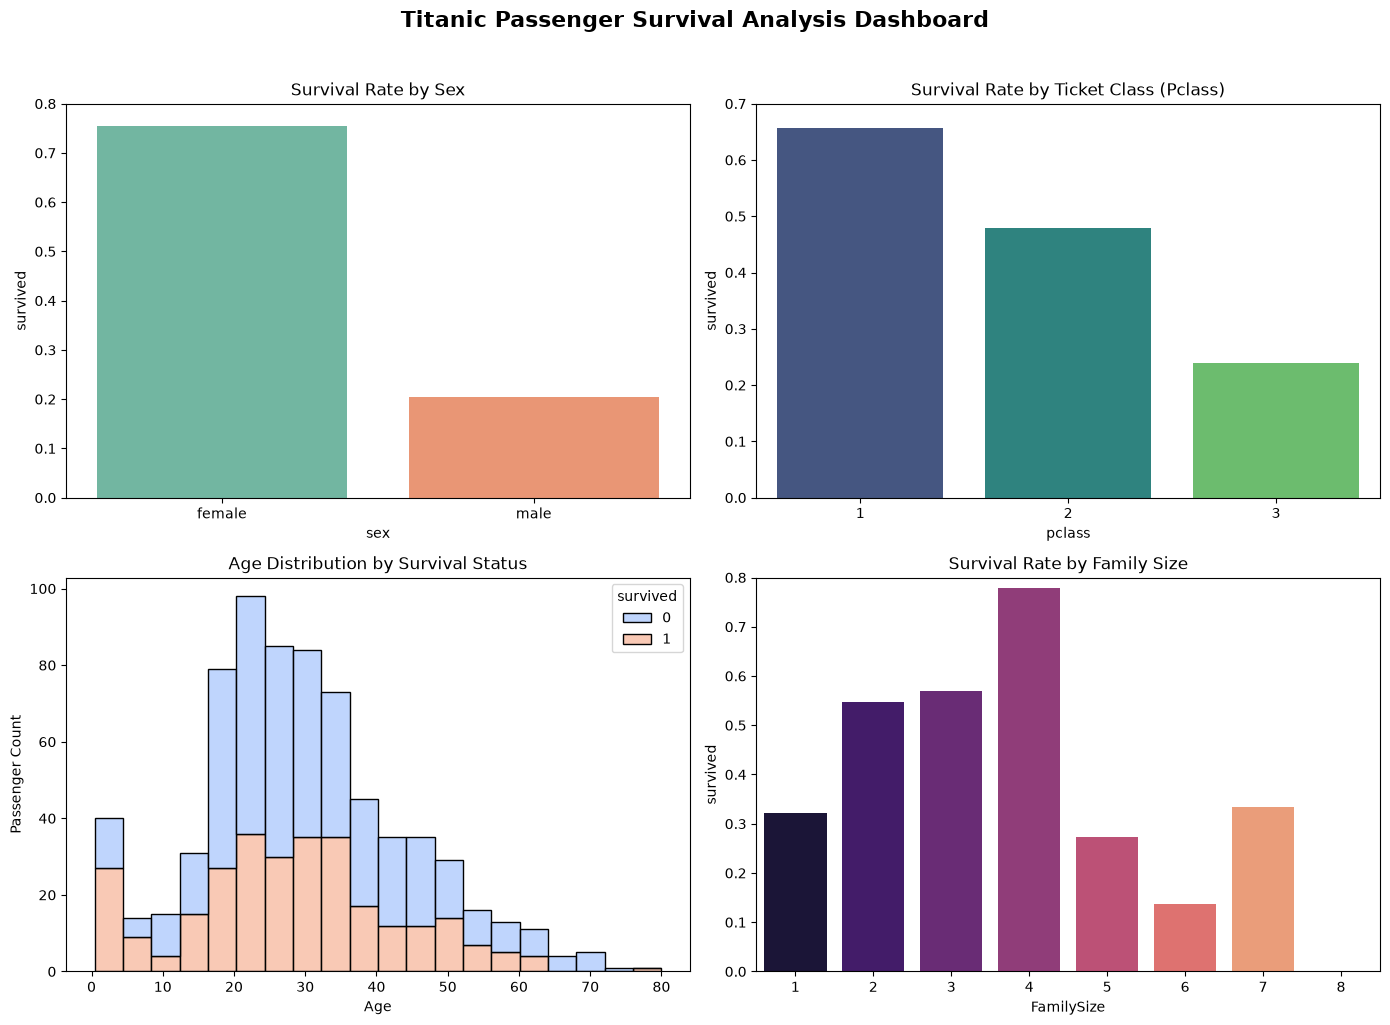

In [100]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Titanic Passenger Survival Analysis Dashboard',fontsize=16,fontweight='bold',y=1.02)

# 1. Survival Rate by Sex
sns.barplot(data=df,x='sex',y='survived',ax=axes[0, 0],palette='Set2',errorbar=None)
axes[0, 0].set_title('Survival Rate by Sex')
axes[0, 0].set_ylim(0,0.8)

# 2. Survival Rate by Ticket Class (Pclass)
sns.barplot(data=df,x='pclass', y='survived', ax=axes[0, 1],palette='viridis',errorbar=None)
axes[0, 1].set_title('Survival Rate by Ticket Class (Pclass)')
axes[0, 1].set_ylim(0,0.7)

# 3. Age Distribution by Survival Status
sns.histplot(data=df,x='age',hue='survived',multiple='stack',bins=20,ax=axes[1, 0],palette='coolwarm')
axes[1, 0].set_title('Age Distribution by Survival Status')
axes[1, 0].set_xlabel('Age')
axes[1, 0].set_ylabel('Passenger Count')

# 4. Survival Rate by Family Size
sns.barplot(data=df,x='FamilySize',y='survived',ax=axes[1, 1],palette='magma',errorbar=None)
axes[1, 1].set_title('Survival Rate by Family Size')
axes[1, 1].set_ylim(0,0.8)

plt.tight_layout()
plt.show()

## 23. Executive Summary Insights: Write down the top 5 most interesting findings from your analysis

1.  **Women and children experienced significantly higher survival rates** compared to adult men, clearly reflecting the historical maritime evacuation priority of "women and children first".
2.  Passenger class was a decisive factor in survival. **First-Class passengers achieved the highest survival probability (~63%)**, whereas Third-Class passengers faced the highest mortality rate, constrained by cabin location and deck access.
3.  **Higher ticket fares strongly correlated with increased survival chances**, as higher-priced tickets directly mapped to superior cabin locations closer to the lifeboat stations.
4.  **Passengers traveling in small family groups (2 to 4 members) had optimal survival rates**. Conversely, solo travelers and those in very large families encountered logistical and coordination difficulties during evacuation.
5.  Survival rates varied by port of embarkation, with passengers **embarking from Cherbourg recording higher survival** proportions due to a larger concentration of upper-class ticket holders.

## 24. Final Conclusion: In a single concise paragraph, explain who was most likely to survive the Titanic disaster and why.

Based on the analysis, the passengers most likely to survive the Titanic disaster were women and children belonging to First Class, as well as those traveling in small family groups with higher ticket fares. This survival advantage was driven by the strict maritime evacuation protocol of prioritizing "women and children first," combined with the structural benefit of upper-deck accommodations that provided immediate and prioritized access to lifeboats.

## 25. Critical Limitations & Future Scope: What are the main limitations of this dataset? What insights cannot be definitively concluded? What additional variables/features would you recommend adding to improve analysis?

### Main Limitations of the Dataset

* **High Proportion of Missing Values:** Critical columns—most notably passenger age and cabin/deck assignments—contain significant missing data, requiring imputation or row dropping that can introduce bias.
* **Coarse-Grained Socioeconomic Proxies:** Social class (`pclass`) and fare prices serve as broad proxies for wealth and status, but lack precise individual income, occupation granularity, or liquid asset data.
* **Lack of Spatial and Temporal Tracking:** The dataset records whether a passenger survived, but lacks data on their exact physical location on the ship when the iceberg was struck, or the precise timeline of their movement to the deck.

---

### Insights That Cannot Be Definitively Concluded

* **The Primary Driver of Survival Disparities:** While statistical models show strong correlations between survival and features like class or sex (due to the "women and children first" protocol), the data cannot definitively isolate whether survival was driven primarily by social protocol, physical proximity to lifeboats, or crew intervention.
* **Individual Behavioral Dynamics:** The dataset cannot capture psychological factors, panic levels, altruism, or individual decision-making during the chaotic evacuation process.
* **Causal Mechanics of Fare Pricing:** Variations in ticket fares (`fare`) across the same class cannot be fully explained without data on ticket purchasing timing, port of embarkation tier, or bundled family tickets.

---

### Recommended Additional Variables for Future Analysis

To improve predictive accuracy and deepen behavioral insights, the following features would be valuable additions:

* **Exact Cabin Location / Deck Coordinate:** Mapping cabins to ship blueprints to calculate the exact physical distance and number of obstacles between a passenger's sleeping quarters and the boat deck.
* **Swimming Ability & Physical Fitness:** Binary or categorical indicators of whether an individual could swim or possessed physical impairments, which heavily influenced survival rates once passengers entered the water.
* **Family Sub-Group Structure:** Granular tracking of traveling groups (e.g., size of dependent children, presence of able-bodied adult males) to analyze how collective decision-making affected survival.
* **Specific Crew Role/Department:** Detailed categorization of crew members (e.g., engine room crew vs. restaurant staff vs. deck officers) rather than a binary crew/passenger split, as their station locations drastically altered their chances of survival.